<h2>Actividad 6 - Clasificador MPL para identificar dígitos manuscritos</h2><br>
Ejemplo de implementación de una red neuronal con Scikit-learn. <a href="https://scikit-learn.org/">https://scikit-learn.org/</a><br>
<b>The digit dataset</b><br>
Base de datos de 250 muestras tomadas de 44 personas diferentes<br>
Origen: <a href="http://archive.ics.uci.edu/ml/datasets/Pen-Based+Recognition+of+Handwritten+Digits">http://archive.ics.uci.edu/ml/datasets/Pen-Based+Recognition+of+Handwritten+Digits</a>
<br>Código Fuente: Gaël Varoquaux
<br>Modificado para documentación por Jaques Grobler
<br>Ejemplo de aplicación: Claudio Morales D.
<br> Adaptado por Hugo Suzuki

In [1]:
# Requiere: scikit-learn, numpy, SciPy
from sklearn import datasets
import matplotlib.pyplot as plt

In [2]:
#Cargar el set de datos
digits = datasets.load_digits()

In [3]:
# digits es un arreglo de elementos diversos (utils.Bunch)
type(digits)

sklearn.utils._bunch.Bunch

In [4]:
# La base de datos se compone de imagenes de dígitos y su dígito correspondiente.
# las imágenes se almacenan en el atributo 'images' del set de datos
print(digits.images)

[[[ 0.  0.  5. ...  1.  0.  0.]
  [ 0.  0. 13. ... 15.  5.  0.]
  [ 0.  3. 15. ... 11.  8.  0.]
  ...
  [ 0.  4. 11. ... 12.  7.  0.]
  [ 0.  2. 14. ... 12.  0.  0.]
  [ 0.  0.  6. ...  0.  0.  0.]]

 [[ 0.  0.  0. ...  5.  0.  0.]
  [ 0.  0.  0. ...  9.  0.  0.]
  [ 0.  0.  3. ...  6.  0.  0.]
  ...
  [ 0.  0.  1. ...  6.  0.  0.]
  [ 0.  0.  1. ...  6.  0.  0.]
  [ 0.  0.  0. ... 10.  0.  0.]]

 [[ 0.  0.  0. ... 12.  0.  0.]
  [ 0.  0.  3. ... 14.  0.  0.]
  [ 0.  0.  8. ... 16.  0.  0.]
  ...
  [ 0.  9. 16. ...  0.  0.  0.]
  [ 0.  3. 13. ... 11.  5.  0.]
  [ 0.  0.  0. ... 16.  9.  0.]]

 ...

 [[ 0.  0.  1. ...  1.  0.  0.]
  [ 0.  0. 13. ...  2.  1.  0.]
  [ 0.  0. 16. ... 16.  5.  0.]
  ...
  [ 0.  0. 16. ... 15.  0.  0.]
  [ 0.  0. 15. ... 16.  0.  0.]
  [ 0.  0.  2. ...  6.  0.  0.]]

 [[ 0.  0.  2. ...  0.  0.  0.]
  [ 0.  0. 14. ... 15.  1.  0.]
  [ 0.  4. 16. ... 16.  7.  0.]
  ...
  [ 0.  0.  0. ... 16.  2.  0.]
  [ 0.  0.  4. ... 16.  2.  0.]
  [ 0.  0.  5. ... 12.  0.  

In [5]:
# Para cada imagen, sabemos qué dígito representa a partir del atributo 'target'
print(digits.target)

[0 1 2 ... 8 9 8]


In [6]:
# ¿Cuántos elementos contienen estos campos?
print("Elementos en digits.images = ", len(digits.images))
print("Elementos en digits.target = ", len(digits.target))

Elementos en digits.images =  1797
Elementos en digits.target =  1797


In [7]:
#¿Cuál es el primer dígito del dataset?
print(digits.images[0])
print(digits.target[0])

[[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]
0


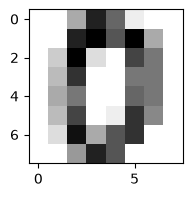

In [8]:
#Podemos visualizar la matriz como una imagen
plt.figure(figsize=(2, 2))
plt.imshow(digits.images[0], cmap=plt.cm.gray_r)
plt.show()

178


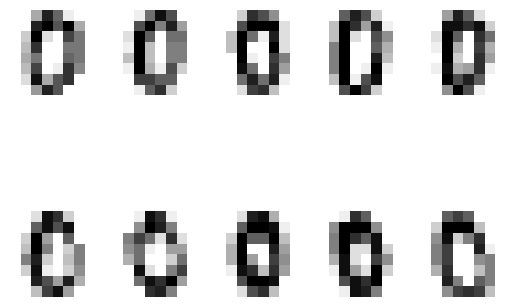

In [9]:
# ¿Cuántos dígitos cero hay en el dataset?

images=[]
for i in range(len(digits.target)):
    if digits.target[i] == 0:
        images.append(digits.images[i])

print(len(images))

# Visualizamos los primeros 10
for index in range(0,10):
    plt.subplot(2, 5, index + 1)
    plt.axis('off')
    plt.imshow(images[index], cmap=plt.cm.gray_r)

plt.show()

In [10]:
# ¿Cuántas muestras hay de cada dígito?
import numpy
muestras = numpy.zeros(10)

for i in range(len(digits.target)):
    for digito in range(10):
            if digits.target[i] == digito:
                muestras[digito] += 1

print(muestras)

[178. 182. 177. 183. 181. 182. 181. 179. 174. 180.]


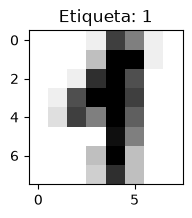

In [11]:
#tomamos nuestro set de datos desde 'digits'
imagenes = digits.images
etiquetas = digits.target

index = 90

plt.figure(figsize=(2, 2))
plt.imshow(imagenes[index], cmap=plt.cm.gray_r)
plt.title('Etiqueta: %i' % etiquetas[index])
plt.show()

In [12]:
# Para aplicar un clasificador sobre estos datos es necesario "aplanar" las imágenes,
# a fin de poner la información en forma de vector:
datos = imagenes.reshape((len(imagenes), -1))

In [13]:
# La primera imagen es:
imagenes[0]

array([[ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.],
       [ 0.,  0., 13., 15., 10., 15.,  5.,  0.],
       [ 0.,  3., 15.,  2.,  0., 11.,  8.,  0.],
       [ 0.,  4., 12.,  0.,  0.,  8.,  8.,  0.],
       [ 0.,  5.,  8.,  0.,  0.,  9.,  8.,  0.],
       [ 0.,  4., 11.,  0.,  1., 12.,  7.,  0.],
       [ 0.,  2., 14.,  5., 10., 12.,  0.,  0.],
       [ 0.,  0.,  6., 13., 10.,  0.,  0.,  0.]])

In [14]:
# El primer dato "aplanado" es
datos[0]

array([ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.,  0.,  0., 13., 15., 10.,
       15.,  5.,  0.,  0.,  3., 15.,  2.,  0., 11.,  8.,  0.,  0.,  4.,
       12.,  0.,  0.,  8.,  8.,  0.,  0.,  5.,  8.,  0.,  0.,  9.,  8.,
        0.,  0.,  4., 11.,  0.,  1., 12.,  7.,  0.,  0.,  2., 14.,  5.,
       10., 12.,  0.,  0.,  0.,  0.,  6., 13., 10.,  0.,  0.,  0.])

In [15]:
# Ahora normalizamos los datos
datos = datos/15. # Transforma el rango 0-15 en un rango 0-1.

In [16]:
# El primer dato normalizado que ingresará al clasificador es
datos[0]

array([0.        , 0.        , 0.33333333, 0.86666667, 0.6       ,
       0.06666667, 0.        , 0.        , 0.        , 0.        ,
       0.86666667, 1.        , 0.66666667, 1.        , 0.33333333,
       0.        , 0.        , 0.2       , 1.        , 0.13333333,
       0.        , 0.73333333, 0.53333333, 0.        , 0.        ,
       0.26666667, 0.8       , 0.        , 0.        , 0.53333333,
       0.53333333, 0.        , 0.        , 0.33333333, 0.53333333,
       0.        , 0.        , 0.6       , 0.53333333, 0.        ,
       0.        , 0.26666667, 0.73333333, 0.        , 0.06666667,
       0.8       , 0.46666667, 0.        , 0.        , 0.13333333,
       0.93333333, 0.33333333, 0.66666667, 0.8       , 0.        ,
       0.        , 0.        , 0.        , 0.4       , 0.86666667,
       0.66666667, 0.        , 0.        , 0.        ])

In [17]:
# Crearemos una red neuronal para un clasificador multicapa (Multi-Layer Perceptron)
# La documentación sobre los parámetros puede encontrarla aquí:
# https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html

from sklearn.neural_network import MLPClassifier
mlp = MLPClassifier(activation='relu', hidden_layer_sizes=(64,),
                    max_iter=100, learning_rate_init=.1)

# Entrenamos la red con n datos
n = 898
mlp.fit(datos[:n], etiquetas[:n])

# Verificamos sus predicciones para los datos restantes
esperado = etiquetas[n:]
prediccion = mlp.predict(datos[n:])

# Y mostramos los resultados.
from sklearn import metrics
print("Reporte del clasificador: \n %s\n %s\n"
      %(mlp, metrics.classification_report(esperado, prediccion)))
print("Matriz de confusión:\n%s" % metrics.confusion_matrix(esperado, prediccion))


Reporte del clasificador: 
 MLPClassifier(hidden_layer_sizes=(64,), learning_rate_init=0.1, max_iter=100)
               precision    recall  f1-score   support

           0       1.00      0.97      0.98        88
           1       0.92      0.86      0.89        91
           2       1.00      0.99      0.99        86
           3       0.95      0.88      0.91        91
           4       0.96      0.92      0.94        92
           5       0.93      0.93      0.93        91
           6       0.93      0.99      0.96        91
           7       0.91      0.96      0.93        89
           8       0.91      0.90      0.90        88
           9       0.84      0.95      0.89        92

    accuracy                           0.93       899
   macro avg       0.94      0.93      0.93       899
weighted avg       0.93      0.93      0.93       899


Matriz de confusión:
[[85  0  0  0  1  0  2  0  0  0]
 [ 0 78  0  1  0  0  0  2  1  9]
 [ 0  0 85  1  0  0  0  0  0  0]
 [ 0  0  0 80

La documentación sobre las métricas de sklearn se encuentra aquí: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_fscore_support.html#sklearn.metrics.precision_recall_fscore_support
Y la explicación de la matriz de confusión la encuentra aquí: https://en.wikipedia.org/wiki/Confusion_matrix



In [18]:
# ¿Cuáles fueron los datos erróneos?
erroneos = []
for i in range(len(prediccion)):
    if esperado[i] != prediccion[i]:
        erroneos.append([esperado[i],prediccion[i]])

erroneos

[[np.int64(8), np.int64(1)],
 [np.int64(5), np.int64(9)],
 [np.int64(5), np.int64(9)],
 [np.int64(4), np.int64(9)],
 [np.int64(1), np.int64(7)],
 [np.int64(8), np.int64(1)],
 [np.int64(8), np.int64(3)],
 [np.int64(8), np.int64(5)],
 [np.int64(3), np.int64(7)],
 [np.int64(1), np.int64(7)],
 [np.int64(1), np.int64(8)],
 [np.int64(1), np.int64(9)],
 [np.int64(4), np.int64(6)],
 [np.int64(4), np.int64(6)],
 [np.int64(5), np.int64(6)],
 [np.int64(2), np.int64(3)],
 [np.int64(4), np.int64(6)],
 [np.int64(5), np.int64(8)],
 [np.int64(1), np.int64(9)],
 [np.int64(1), np.int64(9)],
 [np.int64(1), np.int64(9)],
 [np.int64(1), np.int64(9)],
 [np.int64(1), np.int64(9)],
 [np.int64(1), np.int64(3)],
 [np.int64(1), np.int64(9)],
 [np.int64(1), np.int64(9)],
 [np.int64(1), np.int64(9)],
 [np.int64(8), np.int64(5)],
 [np.int64(8), np.int64(9)],
 [np.int64(6), np.int64(1)],
 [np.int64(7), np.int64(9)],
 [np.int64(8), np.int64(1)],
 [np.int64(9), np.int64(7)],
 [np.int64(8), np.int64(1)],
 [np.int64(9),

Desafío 1: Entrenando la red neuronal
A partir del ejemplo, y utilizando los parámetros por defecto, ejercite con distintas proporciones entre datos de entrenamiento y datos para validación.
1. ¿Cuál es la mínima cantidad de datos de entrenamiento que permiten una precisión por encima de 0.9 para cada dígito leído?
2. ¿Es posible alcanzar una precisión por encima de 0.95 para cada dígito leído?¿Con cuántos datos?
3. Utilizando la mitad de los datos para entrenamiento, varíe los parámetros del clasificador. ¿Qué efecto tienen el cambio de la función de activación, el número de capas ocultas, el número de iteraciones y la tasa de aprendizaje?

### Resolución del Desafío 1

Usamos `MLPClassifier()` **con sus parámetros por defecto**: una capa oculta de 100 neuronas, activación
`relu`, optimizador `adam`, `learning_rate_init=0.001` y `max_iter=200`.

Como "precisión para cada dígito" tomamos la columna *precision* del reporte de clasificación. Lo que se pide
es que **todos** los dígitos la superen, así que miramos la **precisión mínima** entre los 10 dígitos.

Una red neuronal parte de pesos aleatorios, y un solo entrenamiento puede salir mejor o peor por azar. Por eso
cada experimento se repite con varias semillas (`random_state`) y se informa el promedio.

In [19]:
import warnings
import numpy as np
import pandas as pd
from sklearn import metrics
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

# Con pocos datos o pocas iteraciones adam avisa que no convergió; lo silenciamos para no llenar la salida
warnings.filterwarnings('ignore', category=ConvergenceWarning)

def precision_por_digito(modelo, X_tr, y_tr, X_te, y_te):
    modelo.fit(X_tr, y_tr)
    return metrics.precision_score(y_te, modelo.predict(X_te), average=None, zero_division=0)

#### Preguntas 1 y 2: cantidad mínima de datos de entrenamiento

**a) División secuencial, como en el ejemplo** (primeras `n` muestras para entrenar, el resto para validar):

In [20]:
semillas = range(5)
tamanos = [100, 200, 300, 400, 500, 600, 700, 800, 900, 1000, 1200, 1400]

filas = []
for n in tamanos:
    precs = np.array([precision_por_digito(MLPClassifier(random_state=s),
                                           datos[:n], etiquetas[:n], datos[n:], etiquetas[n:])
                      for s in semillas])
    minimos = precs.min(axis=1)
    filas.append({'n entrenamiento': n,
                  'precisión mínima (prom.)': minimos.mean(),
                  'dígito más débil': int(np.bincount(precs.argmin(axis=1)).argmax())})

secuencial = pd.DataFrame(filas)
secuencial.round(3)

,n entrenamiento,precisión mínima (prom.),dígito más débil
0,100,0.566,9
1,200,0.579,9
2,300,0.650,9
3,400,0.745,9
4,500,0.798,9
5,600,0.846,8
6,700,0.862,9
7,800,0.864,9
8,900,0.859,9
9,1000,0.860,9


Con la división secuencial la condición **no se cumple nunca**. La precisión mínima llega como máximo a
**0.864** (con 800 datos) y luego baja. El dígito que falla casi siempre es el **9** (a veces el 8). El
dataset está ordenado por persona que escribió, así que las últimas muestras vienen de gente cuya letra la red
nunca vio al entrenar. Además, cuando `n` es grande quedan pocas muestras de validación por dígito, y cada
error pesa más en la precisión.

**b) División aleatoria y estratificada.** Mezclamos los datos y mantenemos la proporción de cada dígito con
`train_test_split(..., stratify=etiquetas)`. Así entrenamiento y validación salen de la misma población. Para
cada `n` probamos 10 particiones/semillas distintas:

In [21]:
semillas = range(10)
tamanos = list(range(300, 1301, 100))

filas = []
for n in tamanos:
    minimos = []
    for s in semillas:
        X_tr, X_te, y_tr, y_te = train_test_split(datos, etiquetas, train_size=n,
                                                  stratify=etiquetas, random_state=s)
        minimos.append(precision_por_digito(MLPClassifier(random_state=s), X_tr, y_tr, X_te, y_te).min())
    minimos = np.array(minimos)
    filas.append({'n entrenamiento': n,
                  'precisión mínima (prom.)': minimos.mean(),
                  'precisión mínima (peor caso)': minimos.min(),
                  '% corridas > 0.90': 100 * (minimos > 0.90).mean(),
                  '% corridas > 0.95': 100 * (minimos > 0.95).mean()})

aleatorio = pd.DataFrame(filas)
aleatorio.round(3)

,n entrenamiento,precisión mínima (prom.),precisión mínima (peor caso),% corridas > 0.90,% corridas > 0.95
0,300,0.862,0.802,10.0,0.0
1,400,0.887,0.828,50.0,0.0
2,500,0.899,0.828,60.0,0.0
3,600,0.901,0.870,50.0,0.0
4,700,0.922,0.881,90.0,0.0
5,800,0.925,0.882,90.0,10.0
6,900,0.928,0.900,90.0,20.0
7,1000,0.927,0.899,90.0,0.0
8,1100,0.930,0.886,90.0,10.0
9,1200,0.929,0.881,80.0,20.0


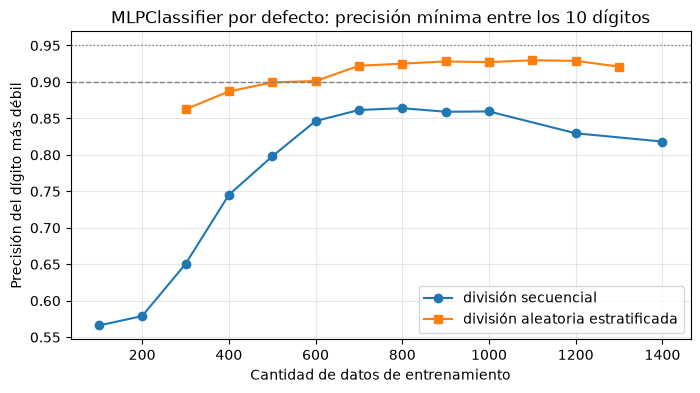

In [22]:
plt.figure(figsize=(8, 4))
plt.plot(secuencial['n entrenamiento'], secuencial['precisión mínima (prom.)'], 'o-', label='división secuencial')
plt.plot(aleatorio['n entrenamiento'], aleatorio['precisión mínima (prom.)'], 's-', label='división aleatoria estratificada')
plt.axhline(0.90, color='gray', ls='--', lw=1)
plt.axhline(0.95, color='gray', ls=':', lw=1)
plt.xlabel('Cantidad de datos de entrenamiento')
plt.ylabel('Precisión del dígito más débil')
plt.title('MLPClassifier por defecto: precisión mínima entre los 10 dígitos')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Un ejemplo concreto para la pregunta 2: el reporte completo de una corrida en la que todos los dígitos superan
0.95.

In [23]:
# Buscamos, entre las semillas, una corrida con n datos de entrenamiento donde todos los dígitos superen 0.95
n = 900
for s in range(10):
    X_tr, X_te, y_tr, y_te = train_test_split(datos, etiquetas, train_size=n, stratify=etiquetas, random_state=s)
    mlp = MLPClassifier(random_state=s).fit(X_tr, y_tr)
    pred = mlp.predict(X_te)
    if metrics.precision_score(y_te, pred, average=None).min() > 0.95:
        print(f'random_state = {s}, n = {n}\n')
        print(metrics.classification_report(y_te, pred))
        break
else:
    print('Ninguna semilla superó 0.95 en todos los dígitos con n =', n)

random_state = 3, n = 900

              precision    recall  f1-score   support

           0       0.98      0.98      0.98        89
           1       0.96      1.00      0.98        91
           2       0.99      1.00      0.99        89
           3       0.98      0.97      0.97        91
           4       0.98      0.98      0.98        90
           5       0.96      0.96      0.96        91
           6       0.99      0.99      0.99        90
           7       1.00      0.99      0.99        89
           8       0.99      0.94      0.96        87
           9       0.96      0.97      0.96        90

    accuracy                           0.98       897
   macro avg       0.98      0.98      0.98       897
weighted avg       0.98      0.98      0.98       897



#### Pregunta 3: efecto de los parámetros usando la mitad de los datos

Entrenamos con la **mitad** de los datos (898 muestras, partición aleatoria estratificada) y validamos con la
otra mitad. Partimos de la configuración por defecto y cambiamos **un parámetro a la vez**. Cada
configuración se promedia sobre 5 semillas. Se mide el *accuracy*, la precisión del dígito más débil, las
iteraciones que hizo el optimizador y el tiempo de entrenamiento.

In [24]:
import time

X_tr, X_te, y_tr, y_te = train_test_split(datos, etiquetas, train_size=0.5, stratify=etiquetas, random_state=0)

def evaluar(**params):
    acc, pmin, iters, tiempo = [], [], [], []
    for s in range(5):
        mlp = MLPClassifier(random_state=s, **params)
        t0 = time.perf_counter()
        mlp.fit(X_tr, y_tr)
        tiempo.append(time.perf_counter() - t0)
        pred = mlp.predict(X_te)
        acc.append(metrics.accuracy_score(y_te, pred))
        pmin.append(metrics.precision_score(y_te, pred, average=None, zero_division=0).min())
        iters.append(mlp.n_iter_)
    return {'accuracy': np.mean(acc), 'precisión mínima': np.mean(pmin),
            'iteraciones': np.mean(iters), 'tiempo [s]': np.mean(tiempo)}

def barrido(nombre, valores):
    filas = [{nombre: str(v), **evaluar(**{nombre: v})} for v in valores]
    return pd.DataFrame(filas).round(3)

print('Configuración por defecto:', {k: round(float(v), 3) for k, v in evaluar().items()})

Configuración por defecto: {'accuracy': 0.972, 'precisión mínima': 0.927, 'iteraciones': 200.0, 'tiempo [s]': 4.182}


**Función de activación** (`activation`):

In [25]:
barrido('activation', ['identity', 'logistic', 'tanh', 'relu'])

,activation,accuracy,precisión mínima,iteraciones,tiempo [s]
0,identity,0.965,0.911,200.0,4.493
1,logistic,0.960,0.891,200.0,4.386
2,tanh,0.968,0.919,200.0,6.095
3,relu,0.972,0.927,200.0,4.773


**Número y tamaño de capas ocultas** (`hidden_layer_sizes`):

In [26]:
barrido('hidden_layer_sizes', [(5,), (10,), (50,), (100,), (300,), (100, 100), (100, 100, 100), (50, 50, 50, 50)])

,hidden_layer_sizes,accuracy,precisión mínima,iteraciones,tiempo [s]
0,"(5,)",0.818,0.646,200.0,1.427
1,"(10,)",0.941,0.841,200.0,1.562
2,"(50,)",0.967,0.919,200.0,2.626
3,"(100,)",0.972,0.927,200.0,4.029
4,"(300,)",0.977,0.937,200.0,45.459
5,"(100, 100)",0.974,0.934,163.2,19.125
6,"(100, 100, 100)",0.973,0.933,111.6,14.492
7,"(50, 50, 50, 50)",0.966,0.927,135.8,3.720


**Número máximo de iteraciones** (`max_iter`):

In [27]:
barrido('max_iter', [5, 10, 20, 50, 100, 200, 500])

,max_iter,accuracy,precisión mínima,iteraciones,tiempo [s]
0,5,0.659,0.461,5.0,0.123
1,10,0.838,0.655,10.0,0.189
2,20,0.901,0.755,20.0,0.464
3,50,0.947,0.858,50.0,2.037
4,100,0.967,0.915,100.0,1.711
5,200,0.972,0.927,200.0,5.493
6,500,0.973,0.929,311.2,7.301


**Tasa de aprendizaje inicial** (`learning_rate_init`):

In [28]:
barrido('learning_rate_init', [0.00001, 0.0001, 0.001, 0.01, 0.1, 0.5, 1.0])

,learning_rate_init,accuracy,precisión mínima,iteraciones,tiempo [s]
0,1e-05,0.241,0.000,200.0,4.679
1,0.0001,0.910,0.763,200.0,4.383
2,0.001,0.972,0.927,200.0,4.127
3,0.01,0.974,0.931,94.0,1.645
4,0.1,0.966,0.927,52.8,1.745
5,0.5,0.247,0.033,47.4,0.930
6,1.0,0.188,0.000,43.4,1.015


#### Conclusiones del Desafío 1

**1. Mínima cantidad de datos para precisión > 0.9 en cada dígito.**
Con la división secuencial del ejemplo no se logra con ninguna cantidad de datos: el 9 se queda en ~0.86. Con
una partición aleatoria estratificada, el promedio de la precisión mínima pasa 0.9 a partir de **~600 datos**
(0.901), aunque solo en la mitad de las corridas. Desde **700 datos de entrenamiento (~39 % del dataset)** se
cumple de forma estable: precisión mínima promedio de 0.922 y 90 % de las corridas por encima de 0.9. Esa es
la respuesta: **unos 700 datos**.

**2. ¿Precisión > 0.95 en cada dígito?**
**Sí es posible, pero no de forma consistente** con los parámetros por defecto. Las primeras corridas que lo
logran aparecen con **800 datos** (10 % de las corridas), y con **900 datos** lo logra el 20 %. Por ejemplo,
con `random_state=3` y 900 datos de entrenamiento todos los dígitos quedan entre 0.96 y 1.00, con accuracy
0.98. En promedio, la precisión mínima se estanca alrededor de 0.93 y no pasa 0.95 aunque se agreguen más
datos: a partir de ese punto el límite es el modelo, no la cantidad de datos.

**3. Efecto de los parámetros (entrenando con la mitad de los datos).** La configuración por defecto da
accuracy 0.972 y precisión mínima 0.927. Los tiempos son orientativos, porque dependen de la carga del equipo.

* **Función de activación:** el efecto es pequeño en este problema. `relu` es la mejor (0.972) y además de
  las más rápidas. `tanh` queda muy cerca (0.968). `identity` (que hace a la red un modelo lineal) llega a
  0.965, lo que muestra que los dígitos de 8×8 son casi linealmente separables. `logistic` es la peor
  (0.960), porque la sigmoide se satura y aprende más lento en las mismas 200 iteraciones.
* **Capas ocultas:** el número de neuronas es lo que más pesa. Con 5 neuronas la red no tiene capacidad
  suficiente (0.818, y el dígito más débil baja a 0.65). Con 50–100 se llega a ~0.97. Con 300 neuronas o
  dos o tres capas de 100 se gana muy poco (0.973–0.977), y el entrenamiento cuesta entre 4 y 10 veces más.
  Las redes más profundas convergen en menos épocas (112–163 frente a 200), pero cada época es más cara.
  Cuatro capas de 50 no mejoran a una sola capa de 100.
* **Número de iteraciones:** con muy pocas épocas la red queda sub-entrenada (5 → 0.659; 20 → 0.901).
  Desde ~100 iteraciones se pasa 0.96. Con 200 aparece el aviso de que no convergió, pero con 500 el
  optimizador se detiene solo, alrededor de la época 311 (criterio de `tol`), y la mejora es mínima
  (0.973). Subir `max_iter` solo ayuda hasta que la pérdida deja de bajar.
* **Tasa de aprendizaje:** es el parámetro más sensible. Si es muy baja (1e-5), la red casi no aprende en
  200 épocas (0.24). Con 1e-4 todavía le faltan épocas (0.910). Entre **0.001 y 0.1** funciona bien, y con
  **0.01** se obtiene el mejor resultado (0.974) en menos de la mitad de las épocas (94). Si es muy alta (0.5
  o 1.0), el optimizador diverge y la red termina prediciendo prácticamente una sola clase (~0.2 de accuracy).

En resumen, para este dataset conviene una sola capa oculta de 50–100 neuronas con `relu`, una tasa de
aprendizaje entre 0.001 y 0.01 y suficientes iteraciones para converger. Lo que más limita el resultado es
cómo se dividen los datos: si en la validación aparecen personas que no estaban en el entrenamiento, la
precisión del 9 cae a ~0.86 sin importar los parámetros.